In [ ]:
import torch
import matplotlib.pyplot as plt

In [ ]:
class MyNetwork(torch.nn.Module):
    def __init__(self, input_size=1, hidden_size=20, output_size=1):
        super().__init__()
        self.fc1 = torch.nn.Linear(input_size, hidden_size)
        self.relu = torch.nn.ReLU()
        self.fc2 = torch.nn.Linear(hidden_size, output_size)
        self.hiddenlayer = torch.nn.Linear(hidden_size, hidden_size)
        self.sigmoid = torch.nn.Sigmoid()
        
        
        self._init_weights_kaiming()
    
    def _init_weights_xavier(self):
        torch.nn.init.xavier_uniform_(self.fc1.weight)
        torch.nn.init.zeros_(self.fc1.bias)
        torch.nn.init.xavier_uniform_(self.fc2.weight)
        torch.nn.init.zeros_(self.fc2.bias)

    def _init_weights_gaussian(self):
        torch.nn.init.normal_(self.fc1.weight, mean=0, std=0.1)
        torch.nn.init.zeros_(self.fc1.bias)
        torch.nn.init.normal_(self.fc2.weight, mean=0, std=0.1)
        torch.nn.init.zeros_(self.fc2.bias)

    def _init_weights_kaiming(self):
        torch.nn.init.kaiming_uniform_(self.fc1.weight, nonlinearity='relu')
        torch.nn.init.zeros_(self.fc1.bias)
        torch.nn.init.kaiming_uniform_(self.fc2.weight, nonlinearity='relu')
        torch.nn.init.zeros_(self.fc2.bias)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.hiddenlayer(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = MyNetwork()
"""
kaiming initialization: N(0, 2/fan_in)
xavier initialization: N(0, 1/fan_in+fan_out)
gaussian initialization: N(0, 1)
"""

'\nkaiming initialization: N(0, 2/fan_in)\nxavier initialization: N(0, 1/fan_in+fan_out)\ngaussian initialization: N(0, 1)\n'

In [ ]:
# Example data (replace with your own)
X = torch.linspace(-100, 100, 100).unsqueeze(1)  # shape: (100, 1)
y = torch.sin(X)                              # shape: (100, 1)



In [ ]:
model = MyNetwork()

# 1. Define loss and optimizer
criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)


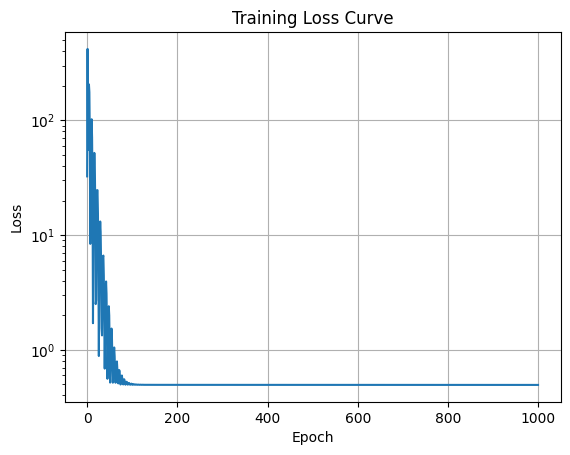

In [ ]:
losses = []

# 2. Training loop
epochs = 1000

for epoch in range(epochs):
    # model.train()
    optimizer.zero_grad()
    output = model(X)
    loss = criterion(output, y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.yscale("log")  # optional, useful if loss drops sharply
plt.grid(True)
plt.show()

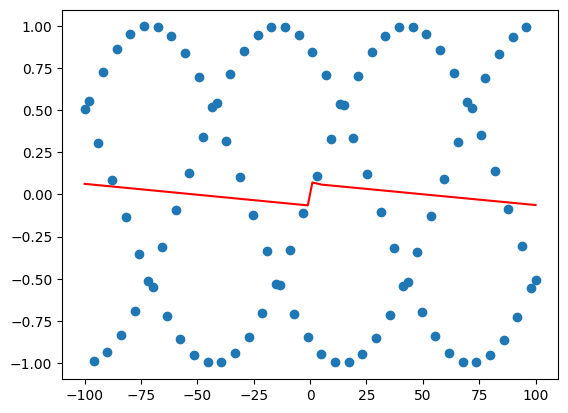

In [ ]:
x = torch.linspace(-100, 100, 100).unsqueeze(1)
model.eval()
with torch.no_grad():
    predicted = model(x)
plt.scatter(X.numpy(), y.numpy(), label='True Data')
plt.plot(x.numpy(), predicted.numpy(), label='Model Prediction', color='red')